In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import os
import torch.backends.cudnn as cudnn
import torch
import torchvision
import torch.nn.functional as F
import numpy as np
import pandas as pd
import time
from datetime import datetime 
import pdb
import yaml
import sys
import glob
import shutil
import tqdm
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import SimpleITK as sitk

In [5]:
sys.path.append('../../MARS')
from MARS.run_lars.utils import model_prediction, my_model

from MARS.run_lars.dataset import dataset, dataset_center, get_datasets, get_image

In [4]:
data_path = '/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/dfs_with_bone_segmentation/train_df_with_ct_bone_segmentation.csv'
data_path_img = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5'
dset = get_datasets('train', norm=None,transform=None, data_path_img=data_path_img, data_path=data_path,
                postfilter_fwhm_xy_mm=6.4, normalize_mean=None, normalize_std=None, target_label_name = 'PET_jco',
                postfilter_fwhm_xy_mm_min=None, postfilter_fwhm_xy_mm_max=None,
                suv_clip_threshold_min=None, suv_clip_threshold_max=None, combine_mipviews = None,
                ct_mode='BONE_SEG_MASK_MULTIPLY', ct_bone_seg_dilation_erosion_pixels=None, ct_bone_seg_dilation_alone_pixels=None)

In [26]:
df = pd.read_csv(data_path)
df_full_metadata = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan.csv')

/tmp/ipykernel_2527347/3632777776.py:2: DtypeWarning: Columns (59) have mixed types. Specify dtype option on import or set low_memory=False.
  df_full_metadata = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/data_scan.csv')


In [29]:
df_full_metadata.columns

Index(['filepath', 'filename', 'filename_header', 'fullfile', 'patient_id',
       'patient_age', 'patient_sex', 'patient_weight', 'smoking_status',
       'accession', 'study_uid', 'series_uid', 'scan_date', 'scan_time',
       'modality', 'matrix_size_1', 'matrix_size_2', 'matrix_size_3',
       'pixel_size_1', 'pixel_size_2', 'pixel_size_3', 'pixel_size_3_str',
       'slice_thickness', 'description_series', 'description_study',
       'admitting_diagnoses', 'protocol_name', 'image_comments', 'body_part',
       'manufacturer', 'manufacturer_model', 'software', 'convolution_kernel',
       'factor_bqml2suv', 'xray_tube_current', 'kvp', 'contrast_agent',
       'patient_position', 'imaging_plane', 'image_orientation',
       'patient_history', 'img_max', 'img_min', 'img_mean', 'img_std',
       'img_sum', 'img_count_nonzeros', 'img_mean_nonzeros',
       'img_std_nonzeros', 'img_sum_nonzeros', 'reconstruction', 'corrections',
       'pixel_unit', 'frame_duration', 'tracer', 'tracer_i

In [ ]:

['patient_position', '']

0        HFS
1        HFS
2        HFS
3        HFS
4        HFS
        ... 
20223    FFS
20224    FFS
20225    FFS
20226    FFS
20227    FFS
Name: patient_position, Length: 20228, dtype: object

In [10]:
df

,filepath,filename,filename_header,fullfile,patient_age,patient_sex,patient_weight,smoking_status,accession,study_uid,...,image_filter,contrast_route,axial_fov,PET_jco,PET_imwg,fullfile_ct,pixel_size_1_ct,pixel_size_2_ct,pixel_size_3_ct,fullfile_ct_bone_segmentation
0,24448091,24448091_pt_2.h5,24448091_pt_2.pkl,24448091/24448091_pt_2.h5,070Y,F,98.431000,UNKNOWN,24448091,1.2.840.114350.2.232.2.798268.2.574394078.1,...,NaN,NaN,1800.00,0.0,0.0,24448091/24448091_ct_1.h5,0.976562,0.976562,5.00,24448091/24448091_ct_1_bone_segmentation.h5
1,5445069,5445069_pt_2.h5,5445069_pt_2.pkl,5445069/5445069_pt_2.h5,052Y,M,83.536000,NO,5445069,1.3.12.2.1107.5.1.4.44843.30000010100219564928...,...,NaN,NaN,1555.00,0.0,0.0,5445069/5445069_ct_3.h5,1.367188,1.367188,5.00,5445069/5445069_ct_3_bone_segmentation.h5
2,29248900,29248900_pt_0.h5,29248900_pt_0.pkl,29248900/29248900_pt_0.h5,048Y,M,63.502940,UNKNOWN,29248900,1.2.840.114350.2.232.2.798268.2.637997691.1,...,NaN,NaN,1857.00,0.0,0.0,29248900/29248900_ct_0.h5,1.523438,1.523438,3.00,29248900/29248900_ct_0_bone_segmentation.h5
3,10103875,10103875_pt_0.h5,10103875_pt_0.pkl,10103875/10103875_pt_0.h5,062Y,M,59.928000,NaN,10103875,1.3.12.2.1107.5.99.1.26055.4.0.2398462621016910,...,NaN,NaN,887.50,0.0,0.0,10103875/10103875_ct_0.h5,0.976562,0.976562,2.50,10103875/10103875_ct_0_bone_segmentation.h5
4,14686352,14686352_pt_0.h5,14686352_pt_0.pkl,14686352/14686352_pt_0.h5,096Y,F,47.000000,NaN,14686352,1.2.840.114350.2.232.2.798268.2.222556711.1,...,NaN,NaN,729.21,1.0,1.0,14686352/14686352_ct_1.h5,0.976562,0.976562,3.27,14686352/14686352_ct_1_bone_segmentation.h5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
733,26890228,26890228_pt_0.h5,26890228_pt_0.pkl,26890228/26890228_pt_0.h5,061Y,F,56.699053,UNKNOWN,26890228,1.2.840.114350.2.232.2.798268.2.611927056.1,...,NaN,NaN,1605.00,1.0,1.0,26890228/26890228_ct_0.h5,1.523438,1.523438,3.00,26890228/26890228_ct_0_bone_segmentation.h5
734,11317060,11317060_pt_0.h5,11317060_pt_0.pkl,11317060/11317060_pt_0.h5,059Y,M,63.502940,UNKNOWN,11317060,1.2.840.114350.2.232.2.798268.2.122758816.1,...,NaN,NaN,1860.00,0.0,0.0,11317060/11317060_ct_0.h5,1.523438,1.523438,3.00,11317060/11317060_ct_0_bone_segmentation.h5
735,8810026,8810026_pt_0.h5,8810026_pt_0.pkl,8810026/8810026_pt_0.h5,075Y,M,72.640000,UNKNOWN,8810026,1.2.840.114350.2.232.2.798268.2.49221970.1,...,NaN,NaN,1440.00,1.0,1.0,8810026/8810026_ct_1.h5,0.976562,0.976562,5.00,8810026/8810026_ct_1_bone_segmentation.h5
736,17900977,17900977_pt_0.h5,17900977_pt_0.pkl,17900977/17900977_pt_0.h5,068Y,F,53.070314,UNKNOWN,17900977,1.2.840.114350.2.232.2.798268.2.283628044.1,...,NaN,NaN,1731.00,0.0,0.0,17900977/17900977_ct_0.h5,1.523438,1.523438,3.00,17900977/17900977_ct_0_bone_segmentation.h5


In [9]:
row = df.iloc[0]
pet_file = row['fullfile']
ct_file = row['fullfile_ct_bone_segmentation']
ct_name_prefix = ct_file.split('/')[1].split('_bone_segmentation.h5')[0]
ct_header = f'{ct_name_prefix}.pkl'
pt_header = row['filename_header']
filepath = row["filepath"]
ct_header_full = os.path.join('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/headers_pkl', str(filepath), ct_header)
pt_header_full = os.path.join('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/headers_pkl', str(filepath), str(row['filename_header']))
ct_dicoms = pd.read_pickle(ct_header_full)
pt_dicoms = pd.read_pickle(pt_header_full)

output = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite'

# ct
file_path_list_ct = []

ct_header_without = ct_header.replace('.pkl', '')
newpath_ct = os.path.join(output, str(filepath), ct_header_without)
os.makedirs(newpath_ct, exist_ok=True)
for i, ds in enumerate(ct_dicoms):
    thispath_ct = os.path.join(newpath_ct, f'slice_{i:03d}.dcm')
    file_path_list_ct.append(thispath_ct)
    ds.save_as(thispath_ct)

# pt
pt_header_without = pt_header.replace('.pkl', '')
newpath_pt = os.path.join(output, str(filepath), pt_header_without)
os.makedirs(newpath_pt, exist_ok=True)
file_path_list_pt = []
for i, ds in enumerate(pt_dicoms):
    thispath_pt = os.path.join(newpath_pt, f'slice_{i:03d}.dcm')
    file_path_list_pt.append(thispath_pt)
    ds.save_as(thispath_pt)


In [ ]:
reader.GetGDCMSeriesFileNames('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite/24448091/24448091_pt_2', )

GDCMSeriesFileNames (0x9852ab0): No Series can be found, make sure your restrictions are not too strong



()

In [19]:
# dcm load using pydicom
patho = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite/24448091/24448091_pt_2/slice_000.dcm'
import pydicom
ds = pydicom.dcmread(patho)


In [22]:
# sitk
reader = sitk.ImageSeriesReader()
reader.SetFileNames(file_path_list_pt)
image = reader.Execute()
#image = reader.Execute(file_path_list_ct)

RuntimeError: Exception thrown in SimpleITK ImageSeriesReader_Execute: /tmp/SimpleITK/Code/IO/src/sitkImageReaderBase.cxx:99:
sitk::ERROR: Unable to determine ImageIO reader for "/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite/24448091/24448091_pt_2/slice_000.dcm"

In [25]:

try:
    ds = pydicom.dcmread("/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite/24448091/24448091_pt_2/slice_000.dcm")
    print("DICOM OK")
    print("TransferSyntax:", ds.file_meta.TransferSyntaxUID)
    print("Has PixelData:", "PixelData" in ds)
except Exception as e:
    print("NOT DICOM:", e)

DICOM OK
TransferSyntax: 1.2.840.10008.1.2.4.90
Has PixelData: False


# Test

In [9]:
data_path = '/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/dfs_with_bone_segmentation/train_df_with_ct_bone_segmentation.csv'
data_path_img = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5'

In [7]:
df_bones = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/dfs_with_bone_segmentation/train_df_with_ct_bone_segmentation.csv')

In [10]:
ds = get_datasets('train', norm=None,transform=None, data_path_img=data_path_img, data_path=data_path,
                postfilter_fwhm_xy_mm=6.4, normalize_mean=None, normalize_std=None, target_label_name = 'PET_jco',
                postfilter_fwhm_xy_mm_min=None, postfilter_fwhm_xy_mm_max=None,
                suv_clip_threshold_min=None, suv_clip_threshold_max=None, combine_mipviews = None,
                ct_mode='BONE_SEG_MASK_MULTIPLY', ct_bone_seg_dilation_erosion_pixels=None, ct_bone_seg_dilation_alone_pixels=None)

In [11]:
ds.df
#ct_img = ds[0][0]

,filepath,filename,filename_header,fullfile,patient_age,patient_sex,patient_weight,smoking_status,accession,study_uid,...,contrast_route,axial_fov,PET_jco,PET_imwg,fullfile_ct,pixel_size_1_ct,pixel_size_2_ct,pixel_size_3_ct,fullfile_ct_bone_segmentation,mipview
0,24448091,24448091_pt_2.h5,24448091_pt_2.pkl,24448091/24448091_pt_2.h5,070Y,F,98.431000,UNKNOWN,24448091,1.2.840.114350.2.232.2.798268.2.574394078.1,...,NaN,1800.00,0.0,0.0,24448091/24448091_ct_1.h5,0.976562,0.976562,5.00,24448091/24448091_ct_1_bone_segmentation.h5,cor
1,5445069,5445069_pt_2.h5,5445069_pt_2.pkl,5445069/5445069_pt_2.h5,052Y,M,83.536000,NO,5445069,1.3.12.2.1107.5.1.4.44843.30000010100219564928...,...,NaN,1555.00,0.0,0.0,5445069/5445069_ct_3.h5,1.367188,1.367188,5.00,5445069/5445069_ct_3_bone_segmentation.h5,cor
2,29248900,29248900_pt_0.h5,29248900_pt_0.pkl,29248900/29248900_pt_0.h5,048Y,M,63.502940,UNKNOWN,29248900,1.2.840.114350.2.232.2.798268.2.637997691.1,...,NaN,1857.00,0.0,0.0,29248900/29248900_ct_0.h5,1.523438,1.523438,3.00,29248900/29248900_ct_0_bone_segmentation.h5,cor
3,10103875,10103875_pt_0.h5,10103875_pt_0.pkl,10103875/10103875_pt_0.h5,062Y,M,59.928000,NaN,10103875,1.3.12.2.1107.5.99.1.26055.4.0.2398462621016910,...,NaN,887.50,0.0,0.0,10103875/10103875_ct_0.h5,0.976562,0.976562,2.50,10103875/10103875_ct_0_bone_segmentation.h5,cor
4,14686352,14686352_pt_0.h5,14686352_pt_0.pkl,14686352/14686352_pt_0.h5,096Y,F,47.000000,NaN,14686352,1.2.840.114350.2.232.2.798268.2.222556711.1,...,NaN,729.21,1.0,1.0,14686352/14686352_ct_1.h5,0.976562,0.976562,3.27,14686352/14686352_ct_1_bone_segmentation.h5,cor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1471,26890228,26890228_pt_0.h5,26890228_pt_0.pkl,26890228/26890228_pt_0.h5,061Y,F,56.699053,UNKNOWN,26890228,1.2.840.114350.2.232.2.798268.2.611927056.1,...,NaN,1605.00,1.0,1.0,26890228/26890228_ct_0.h5,1.523438,1.523438,3.00,26890228/26890228_ct_0_bone_segmentation.h5,sag
1472,11317060,11317060_pt_0.h5,11317060_pt_0.pkl,11317060/11317060_pt_0.h5,059Y,M,63.502940,UNKNOWN,11317060,1.2.840.114350.2.232.2.798268.2.122758816.1,...,NaN,1860.00,0.0,0.0,11317060/11317060_ct_0.h5,1.523438,1.523438,3.00,11317060/11317060_ct_0_bone_segmentation.h5,sag
1473,8810026,8810026_pt_0.h5,8810026_pt_0.pkl,8810026/8810026_pt_0.h5,075Y,M,72.640000,UNKNOWN,8810026,1.2.840.114350.2.232.2.798268.2.49221970.1,...,NaN,1440.00,1.0,1.0,8810026/8810026_ct_1.h5,0.976562,0.976562,5.00,8810026/8810026_ct_1_bone_segmentation.h5,sag
1474,17900977,17900977_pt_0.h5,17900977_pt_0.pkl,17900977/17900977_pt_0.h5,068Y,F,53.070314,UNKNOWN,17900977,1.2.840.114350.2.232.2.798268.2.283628044.1,...,NaN,1731.00,0.0,0.0,17900977/17900977_ct_0.h5,1.523438,1.523438,3.00,17900977/17900977_ct_0_bone_segmentation.h5,sag


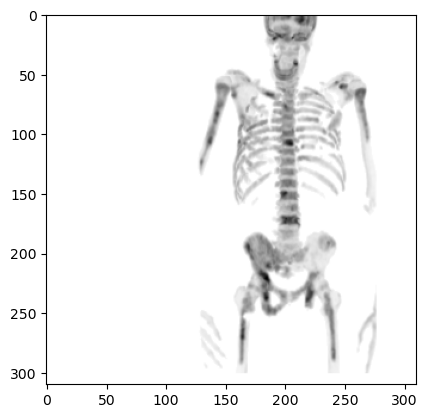

In [12]:
img = ds[8][0]
plt.imshow(img[0,:,:], cmap='gray_r')

In [17]:
# make gif of all slices using img

import imageio
images = []

img = ds[8][0].cpu().numpy()

normed = (img - img.min()) / (img.max() - img.min()) * 255
normed = normed.astype(np.uint8)
for i in range(img.shape[0]):
    slice_img = normed[i,:,:]
    images.append(slice_img)
imageio.mimsave('/gpfs/data/mayerhoeferlab/projects/myeloma/testdir/ct_segmentation_slices.gif', images, fps=5)